In [1]:
import sys

sys.path.append("../src")
from configs.load_config import load_config
from data_processing.load import load_dataset
from models.build import build_model
from training.train import train_torch, sample_numpyro
import matplotlib.pyplot as plt
from training.evaluate import evaluate_model, evaluate_numpyro
import importlib
import training.plot as load_plot

importlib.reload(load_plot)
from training.plot import (
    plot_qr_hdi_prediction,
    plot_quantile_calibration,
    plot_residuals,
    plot_qr_hdi_prediction,
    plot_quantile_calibration,
    plot_first_layer_feature_posteriors,
    plot_bnn_weight_posteriors,
    plot_posterior_predictive_vs_likelihood,
    plot_stacked_hdi_intervals,
    plot_pit_histogram,
    extract_quantile_curves,
    evaluate_and_plot_qr_ensemble_medians,
    plot_posterior_predictive_family,
    plot_qr_hdi_prediction_ensemble,
)
import torch
import numpy as np
import numpyro
from data_processing.utils import (
    load_torch_model,
    load_checkpoint,
    save_scaler_params,
    approximate_qr_intervals,
)
import pandas as pd

import imageio.v2 as imageio
import io
from IPython.display import Image, display

In [2]:
# model_cfg = load_config("../configs/model/bnn_gen_model_nowcast_03_weighted.yaml")
# data_cfg = load_config(model_cfg.data.path)
# file_name = "model_mw_gamma_extended_site1_2026-02-16_13-57-35_nowcast_ELSPOT_NO3"


model_cfg = load_config("../configs/model/bnn_gen_model_nowcast_01_weighted.yaml")
data_cfg = load_config(model_cfg.data.path)
file_name = "model_mw_gamma_extended_2026-02-16_11-27-43_nowcast_ELSPOT_NO1"

# model_cfg = load_config("../configs/model/torch_model_quantile.yaml")
# data_cfg = load_config(model_cfg.data.path)
# file_name = "WindPowerQuantile_2026-01-13_13-43-06_nowcast_gen_ELSPOT_NO3"

In [3]:
data = load_dataset(data_cfg)

ELSPOT NO1
Loading nowcast data for ELSPOT NO1...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:722: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-10-26 22:00:00


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Maintenance hours in operational period: 8
Preprocessing done. X_train shape: (19122, 6, 10)
Preprocessing done. X_test shape: (2160, 6, 10)


In [4]:
N, S, F = data["X_train"].shape

In [5]:
from data_processing.load import load_scaler_params

scalar_params = load_scaler_params(model_cfg.data.bid_zone)
print(
    "\nMax capacity in bid zone (MW): ",
    sum(
        (data["sites_meta"] * scalar_params["site_scaler_params"]["std"])
        + scalar_params["site_scaler_params"]["mean"]
    ),
)

Loaded scaler parameters for ELSPOT NO1 and nowcast
  Saved at: 2026-02-16 18:15:34
  Split time: 2025-01-01 00:00:00+01:00

Max capacity in bid zone (MW):  [405.7]


In [6]:
print(
    "Wind turbines cut off at ~25km/h, standardized",
    (25 - scalar_params["scaler_params"]["mean"]["wind_speed_10m"])
    / scalar_params["scaler_params"]["std"]["wind_speed_10m"],
)

Wind turbines cut off at ~25km/h, standardized 15.924558781873635


In [7]:
weather_stats = {
    col: [
        mean_weather.round(3).item(),
        min_weather.round(3).item(),
        max_weather.round(3).item(),
    ]
    for col, mean_weather, min_weather, max_weather in zip(
        data["feature_cols"],
        data["X_train"].mean(axis=0).mean(axis=0),
        data["X_train"].min(axis=0).min(axis=0),
        data["X_train"].max(axis=0).max(axis=0),
    )
}

weather_mean = data["X_train"].mean(axis=0).mean(axis=0)

In [8]:
construct_N = 361
select_col = "wind_speed_10m"  #  "wind_direction_10m_y"

# average weather in correct shape
weather_constructed = np.broadcast_to(weather_mean, (construct_N, S, F)).copy()


if select_col == "wind_speed_10m":
    vals = np.linspace(
        weather_stats[select_col][1],  # - 5,
        weather_stats[select_col][2],  # + 50,
        construct_N,
    )
    weather_constructed[:, :, -3:] = vals[:, None, None]
elif select_col in ["wind_direction_10m_x", "wind_direction_10m_y"]:
    vals = np.linspace(0, 360, construct_N)
    angles_rad = np.deg2rad(vals)
    x = np.cos(angles_rad)
    y = np.sin(angles_rad)

    idx_x = data["feature_cols"].index("wind_direction_10m_x")
    idx_y = data["feature_cols"].index("wind_direction_10m_y")

    weather_constructed[:, :, idx_x] = x[:None, None]
    weather_constructed[:, :, idx_y] = y[:None, None]


else:
    vals = np.linspace(
        weather_stats[select_col][1],  # - 5,
        weather_stats[select_col][2],  # + 50,
        construct_N,
    )
    idx = data["feature_cols"].index(select_col)
    weather_constructed[:, :, idx] = vals[:None, None]

data_constructed = data.copy()
data_constructed["X_test"] = weather_constructed
data_constructed["Y_test_gen"] = data_constructed["Y_test_gen"][:construct_N]

In [9]:
median_list = []
hdi_list = []
percentile_list = []
y_pred_list = []

for member in range(15):

    if model_cfg.backend == "torch":
        # Quantiles
        if model_cfg.params.quantiles is None:
            quantiles = torch.linspace(0, 1, 51)
        else:
            quantiles = torch.tensor(model_cfg.params.quantiles)

        model, checkpoint = load_torch_model(
            file_name=file_name,
        )

        metrics, y_pred = evaluate_model(
            model=model,
            data=data,
            quantiles=quantiles,
            model_cfg=checkpoint["model_cfg"],
            data_cfg=data_cfg,
            member=member,
        )

        hdis, _, _, _ = approximate_qr_intervals(
            Y_pred=y_pred,
            taus=quantiles,
            cred_mass=0.95,
        )

        # Extract curves, TODO: not 95% CI!!
        median, lower, upper = extract_quantile_curves(
            Y_pred_quantiles=y_pred,
            quantiles=quantiles,
            median_q=0.5,
            lower_q=0.02,
            upper_q=0.98,
        )

        percentiles = np.stack([lower, upper], axis=1)

        median_list.append(median)
        hdi_list.append(hdis.T)
        percentile_list.append(percentiles)
        y_pred_list.append(y_pred)

    elif model_cfg.backend == "numpyro":

        checkpoint = load_checkpoint(file_name=file_name)
        model = build_model(checkpoint["model_cfg"], data_constructed)
        samples = checkpoint["samples"]
        metrics, y_pred, predictive, median, percentiles, hdis = evaluate_numpyro(
            model=model,
            samples=checkpoint["samples"],
            rng_key_predict=checkpoint["rng_key_predict"],
            data=data_constructed,
            model_cfg=checkpoint["model_cfg"],
            member=member,
        )
        if member == 0:
            print(metrics)

        median_list.append(median)
        hdi_list.append(hdis)
        percentile_list.append(percentiles)
        y_pred_list.append(y_pred)

    # print(metrics)

    if data_cfg.dataset == "nowcast":
        # validate on nowcast, only one loop, otherwise validation on all ensemble members
        print("break")
        break


# assert checkpoint["model_cfg"] == model_cfg

Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-02-16_11-27-43_nowcast_ELSPOT_NO1.pkl
RMSE train: 45.064976
CRPS train:  22.35247510035614
RMSE val: 174.2722
CRPS val:  119.85840677108504 

{'rmse_median': np.float32(174.2722), 'coverage_025_975': np.float64(0.48753462603878117), 'coverage_0_50': np.float64(0.6011080332409973), 'crps': np.float64(119.85840677108504)}
break


In [ ]:
change_fix_point = {"relative_humidity_2m": 2}
weather_constructed = np.broadcast_to(weather_mean, (10, S, F)).copy()
fix_point_col, fix_point_value = next(iter(change_fix_point.items()))
fix_point_col_idx = data["feature_cols"].index(fix_point_col)
weather_constructed[:, :, fix_point_col_idx] = fix_point_value

array([[2., 2., 2., 2., 2., 2.],
       [2., 2., 2., 2., 2., 2.],
       [2., 2., 2., 2., 2., 2.],
       [2., 2., 2., 2., 2., 2.],
       [2., 2., 2., 2., 2., 2.],
       [2., 2., 2., 2., 2., 2.],
       [2., 2., 2., 2., 2., 2.],
       [2., 2., 2., 2., 2., 2.],
       [2., 2., 2., 2., 2., 2.],
       [2., 2., 2., 2., 2., 2.]], dtype=float32)

In [11]:
# TODO put into utils.py
def run_plausibility_sweep_speed_dir_2d(
    Ns,
    Nd,
    data,
    data_cfg,
    model_cfg,
    file_name,
    speed_offset=0.0,
    change_fix_point=None,
):
    speed_col = "wind_speed_10m"
    dir_x_col = "wind_direction_10m_x"
    dir_y_col = "wind_direction_10m_y"

    _, S, F = data["X_train"].shape
    backend = getattr(model_cfg, "backend", None)
    feature_cols = data["feature_cols"]

    weather_stats = {
        col: [
            min_weather.round(3).item(),
            max_weather.round(3).item(),
        ]
        for col, min_weather, max_weather in zip(
            data["feature_cols"],
            data["X_train"].min(axis=0).min(axis=0),
            data["X_train"].max(axis=0).max(axis=0),
        )
    }

    weather_mean = data["X_train"].mean(axis=0).mean(axis=0)

    # 1: define sweep axes
    speeds = np.linspace(
        weather_stats[speed_col][0] - speed_offset,
        weather_stats[speed_col][1] + speed_offset,
        Ns,
    )

    directions_deg = np.linspace(0.0, 360.0, Nd, endpoint=True)
    angles_rad = np.deg2rad(directions_deg)
    xdir = np.cos(angles_rad)
    ydir = np.sin(angles_rad)

    # 2: build full Cartesian product grid
    # grid index k = i_dir*Ns + j_speed
    s_grid = np.tile(speeds, Nd)  # (Nd*Ns,)
    dir_x_grid = np.repeat(xdir, Ns)
    dir_y_grid = np.repeat(ydir, Ns)

    Ngrid = Nd * Ns

    weather_constructed = np.broadcast_to(weather_mean, (Ngrid, S, F)).copy()
    # assumes: last 3 features represent wind speed(s)
    weather_constructed[:, :, -3:] = s_grid[:, None, None]
    # set direction x/y
    idx_x = feature_cols.index(dir_x_col)
    idx_y = feature_cols.index(dir_y_col)
    weather_constructed[:, :, idx_x] = dir_x_grid[:, None]
    weather_constructed[:, :, idx_y] = dir_y_grid[:, None]

    if change_fix_point is not None:
        assert (
            isinstance(change_fix_point, dict) and len(change_fix_point) == 1
        ), "change_fix_point has to be a dictionary with exactly one key-value pair"
        fix_point_col, fix_point_value = next(iter(change_fix_point.items()))
        fix_point_col_idx = data["feature_cols"].index(fix_point_col)
        weather_constructed[:, :, fix_point_col_idx] = fix_point_value

    data_constructed = data.copy()
    data_constructed["X_test"] = weather_constructed
    data_constructed["Y_test_gen"] = np.ones((Ngrid,))  # No meaningful test data here
    assert data_constructed["X_test"].shape[0] == Ngrid
    assert data_constructed["Y_test_gen"].shape[0] == Ngrid

    # 3: run ensemble members
    # TODO: run on nowcast or on forecast?
    median_members = []
    hdi_members = []
    percentile_members = []
    y_pred_members = []

    for member in range(15):
        if backend == "torch":
            import torch

            taus = torch.linspace(0, 1, 51)
            model, checkpoint = load_torch_model(file_name=file_name)

            metrics, y_pred = evaluate_model(
                model=model,
                data=data_constructed,
                quantiles=taus,
                model_cfg=checkpoint["model_cfg"],
                data_cfg=data_cfg,
                member=member,
            )

            hdis, _, _, _ = approximate_qr_intervals(
                Y_pred=y_pred,
                taus=taus,
            )

            median, lower, upper = extract_quantile_curves(
                Y_pred_quantiles=y_pred,
                quantiles=taus,
            )

            percentiles = np.stack([lower, upper], axis=1)

            median_members.append(np.asarray(median))
            hdi_members.append(np.asarray(hdis).T)
            percentile_members.append(np.asarray(percentiles))
            y_pred_members.append(y_pred)

        elif backend == "numpyro":
            checkpoint = load_checkpoint(file_name=file_name)
            model = build_model(checkpoint["model_cfg"], data_constructed)

            metrics, y_pred, predictive, median, percentiles, hdis = evaluate_numpyro(
                model=model,
                samples=checkpoint["samples"],
                rng_key_predict=checkpoint["rng_key_predict"],
                data=data_constructed,
                model_cfg=checkpoint["model_cfg"],
                member=member,
            )

            median_members.append(np.asarray(median))
            hdi_members.append(np.asarray(hdis))
            percentile_members.append(np.asarray(percentiles))
            y_pred_members.append(y_pred)
        else:
            raise ValueError(f"Unknown backend: {backend}")

        # nowcast behavior
        if getattr(data_cfg, "dataset", None) == "nowcast":
            break

    median_members = np.stack(median_members, axis=0)  # (M, Ngrid, ...)
    percentile_members = np.stack(
        percentile_members, axis=0
    )  # (M, Ngrid, ..., 2) or similar

    # 4: ensemble summaries
    median_mean = median_members.mean(axis=0)  # (Ngrid, ...)
    median_mean_grid = median_mean.reshape(
        Nd, Ns, *median_mean.shape[1:]
    )  # first dimension is the swept samples

    return {
        "speeds": speeds,  # (Ns,)
        "directions_deg": directions_deg,  # (Nd,)
        "median_mean_grid": median_mean_grid,  # (Nd, Ns, ...)
    }


def run_plausibility_sweep(
    construct_N,
    select_col,
    weather_mean,
    weather_stats,
    data,
    data_cfg,
    model_cfg,
    file_name,
    offset=0,
    n_members=15,
    cred_mass=0.95,
):
    _, S, F = data["X_train"].shape
    backend = getattr(model_cfg, "backend", None)

    # 1: construct sweep inputs
    weather_constructed = np.broadcast_to(weather_mean, (construct_N, S, F)).copy()

    feature_cols = data["feature_cols"]

    if select_col == "wind_speed_10m":
        vals = np.linspace(
            weather_stats[select_col][1] - offset,
            weather_stats[select_col][2] + offset,
            construct_N,
        )
        weather_constructed[:, :, -3:] = vals[:, None, None]

    elif select_col in ["wind_direction_10m_x", "wind_direction_10m_y"]:
        # sweep direction 0..360 and map to x/y
        vals = np.linspace(0, 360, construct_N)
        angles_rad = np.deg2rad(vals)
        xdir = np.cos(angles_rad)
        ydir = np.sin(angles_rad)

        idx_x = feature_cols.index("wind_direction_10m_x")
        idx_y = feature_cols.index("wind_direction_10m_y")

        weather_constructed[:, :, idx_x] = xdir[:, None]
        weather_constructed[:, :, idx_y] = ydir[:, None]

    else:
        vals = np.linspace(
            weather_stats[select_col][1], weather_stats[select_col][2], construct_N
        )
        idx = feature_cols.index(select_col)
        weather_constructed[:, :, idx] = vals[:, None]

    data_constructed = data.copy()
    data_constructed["X_test"] = weather_constructed
    data_constructed["Y_test_gen"] = data_constructed["Y_test_gen"][:construct_N]

    # 2: run members
    median_members = []
    hdi_members = []
    percentile_members = []
    y_pred_members = []

    for member in range(n_members):

        if backend == "torch":
            taus = torch.linspace(0, 1, 51)

            model, checkpoint = load_torch_model(file_name=file_name)

            metrics, y_pred = evaluate_model(
                model=model,
                data=data_constructed,
                quantiles=taus,
                model_cfg=checkpoint["model_cfg"],
                data_cfg=data_cfg,
                member=member,
            )

            hdis, _, _, _ = approximate_qr_intervals(
                Y_pred=y_pred,
                taus=taus,
                cred_mass=cred_mass,
            )

            median, lower, upper = extract_quantile_curves(
                Y_pred_quantiles=y_pred,
                quantiles=taus,
            )

            percentiles = np.stack([lower, upper], axis=1)

            median_members.append(np.asarray(median))
            hdi_members.append(np.asarray(hdis).T)
            percentile_members.append(np.asarray(percentiles))
            y_pred_members.append(y_pred)

        elif backend == "numpyro":
            checkpoint = load_checkpoint(file_name=file_name)
            model = build_model(checkpoint["model_cfg"], data_constructed)

            metrics, y_pred, predictive, median, percentiles, hdis = evaluate_numpyro(
                model=model,
                samples=checkpoint["samples"],
                rng_key_predict=checkpoint["rng_key_predict"],
                data=data_constructed,
                model_cfg=checkpoint["model_cfg"],
                member=member,
            )

            median_members.append(np.asarray(median))
            hdi_members.append(np.asarray(hdis))
            percentile_members.append(np.asarray(percentiles))
            y_pred_members.append(y_pred)

        else:
            raise ValueError(f"Unknown backend: {backend}")

        # nowcast behavior
        if getattr(data_cfg, "dataset", None) == "nowcast":
            break

    median_members = np.stack(median_members, axis=0)
    percentile_members = np.stack(percentile_members, axis=0)

    # 3: ensemble summaries
    median_mean = median_members.mean(axis=0)

    return {
        "select_col": select_col,
        "vals": vals,
        "data_constructed": data_constructed,
        "median_members": median_members,
        "percentile_members": percentile_members,
        "hdi_members": hdi_members,
        "y_pred_members": y_pred_members,
        "median_mean": median_mean,
    }


# 1D plausibility sweep, not used right now
def plot_plausibility_sweep(
    vals,
    median,
    offset=0,
    xlabel="Selected variable",
    ylabel="Median prediction",
    title="Plausibility check: 1D sweep",
    show_points=True,
):
    x = np.asarray(vals).reshape(-1)
    y = np.asarray(median).reshape(-1)

    idx = np.argsort(x)
    x, y = x[idx], y[idx]

    _, ax = plt.subplots(figsize=(7.5, 4.5))

    if show_points:
        ax.scatter(x, y, s=18, alpha=0.55)

    if offset != 0:
        ax.axvspan(
            vals[0] + offset,
            vals[-1] - offset,
            alpha=0.2,
            label="Interval covered by training data",
        )

    ax.plot(x, y, lw=1.5, alpha=0.8, label="Median")

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()

    return x, y


# TODO put into plot.py
def plot_plausibility_polar(
    speeds,
    directions_deg,
    power_grid,
    title="Plausibility check: speed × direction",
    levels=20,
    cmap="viridis",
    vmax=1800,
):

    # Convert to radians for polar axis
    theta = np.radians(directions_deg)

    # Create meshgrid in the shape contourf expects
    R, TH = np.meshgrid(speeds, theta)  # both shape (len(theta), len(speeds))

    fig, ax = plt.subplots(figsize=(8.5, 6), subplot_kw=dict(projection="polar"))
    ax.set_theta_zero_location("N")  # 0 degree at North
    ax.set_theta_direction(-1)  # clockwise
    print(vmax)

    level_values = np.linspace(0, vmax, levels)
    cf = ax.contourf(
        TH, R, power_grid, cmap=cmap, vmin=0, vmax=vmax, levels=level_values
    )
    cbar = fig.colorbar(cf, ax=ax, pad=0.10)
    cbar.set_label("Predicted generated power")

    ax.set_title(title)
    ax.set_rlabel_position(135)
    ax.grid(alpha=0.25)
    ax.text(
        0.5,
        -0.12,
        "Angle: wind direction (degrees), radius: wind speed (m/s)",
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=10,
    )
    plt.tight_layout()

    return fig, ax


# TODO put in plot.py
def animate_polar_plot(
    data,
    change_fix_point_col="air_pressure_at_sea_level",
    N_fix_point=6,
    N_speed=50,
    N_direction=90,
    speed_offset=0,
):
    weather_stats = {
        col: [
            min_weather.round(3).item(),
            max_weather.round(3).item(),
        ]
        for col, min_weather, max_weather in zip(
            data["feature_cols"],
            data["X_train"].min(axis=0).min(axis=0),
            data["X_train"].max(axis=0).max(axis=0),
        )
    }

    vals = np.linspace(
        weather_stats[change_fix_point_col][0],
        weather_stats[change_fix_point_col][1],
        N_fix_point,
    )

    vals = np.sort(np.concatenate([vals, [0]]))

    frames = []
    max_list = []
    outs = []
    original_vals = []

    for val in vals:

        original_val = (
            val * scalar_params["scaler_params"]["std"][change_fix_point_col]
        ) + scalar_params["scaler_params"]["mean"][change_fix_point_col]

        out_2d = run_plausibility_sweep_speed_dir_2d(
            Ns=N_speed,
            Nd=N_direction,
            data=data,
            data_cfg=data_cfg,
            model_cfg=model_cfg,
            file_name=file_name,
            speed_offset=speed_offset,
            change_fix_point={change_fix_point_col: val},
        )
        max_list.append(np.max(out_2d["median_mean_grid"]))
        outs.append(out_2d)
        original_vals.append(original_val)

    vmax = np.max(max_list)

    for out_2d, original_val in zip(outs, original_vals):

        if "humidity" in change_fix_point_col:
            title = f"Plausibility check: speed x direction ({model_cfg.data.bid_zone}, {change_fix_point_col} {round(original_val * 100, 1) }%)"
        elif "temperature" in change_fix_point_col:
            title = f"Plausibility check: speed x direction ({model_cfg.data.bid_zone}, {change_fix_point_col} {round(original_val - 273.14, 1) }°C)"
        elif "pressure" in change_fix_point_col:
            title = f"Plausibility check: speed x direction ({model_cfg.data.bid_zone}, air pressure {round(original_val /100, 1) }hPa)"
        else:
            title = f"Plausibility check: speed x direction ({model_cfg.data.bid_zone}, {change_fix_point_col} {round(original_val, 1) })"

        fig, ax = plot_plausibility_polar(
            out_2d["speeds"],
            out_2d["directions_deg"],
            out_2d["median_mean_grid"],
            title=title,
            vmax=vmax,
        )
        buf = io.BytesIO()
        plt.savefig(buf, format="png")
        plt.close()

        buf.seek(0)
        frames.append(imageio.imread(buf))

    # Save gif
    imageio.mimsave(
        f"animation_{model_cfg.data.bid_zone}_{change_fix_point_col}.gif",
        frames,
        fps=1,
        # loop=1,
    )

In [12]:
animate_polar_plot(
    data,
    change_fix_point_col="air_pressure_at_sea_level",  # "air_temperature_2m",  #
)

Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-02-16_11-27-43_nowcast_ELSPOT_NO1.pkl
RMSE train: 45.064976
CRPS train:  22.35247510035614
RMSE val: 247.38583932541923
CRPS val:  185.96718026959584 

Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-02-16_11-27-43_nowcast_ELSPOT_NO1.pkl
RMSE train: 45.064976
CRPS train:  22.35247510035614
RMSE val: 249.87554348751266
CRPS val:  189.44041323582704 

Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-02-16_11-27-43_nowcast_ELSPOT_NO1.pkl
RMSE train: 45.064976
CRPS train:  22.35247510035614
RMSE val: 259.05490868582865
CRPS val:  194.08343388396895 

Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-02-16_11-27-43_nowcast_ELSPOT_NO1.pkl
RMSE train: 45.064976
CRPS train:  22.35247510035614
RMSE val: 291.2846934466563
CRPS val:  220.35653759985257 

Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-02-16_11-27-43_nowcast_

Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-02-16_11-27-43_nowcast_ELSPOT_NO1.pkl
RMSE train: 45.064976
CRPS train:  22.35247510035614
RMSE val: 159.95712
CRPS val:  112.29732437339962 

Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-02-16_11-27-43_nowcast_ELSPOT_NO1.pkl
RMSE train: 45.064976
CRPS train:  22.35247510035614
RMSE val: 217.5747
CRPS val:  161.54998550421084 



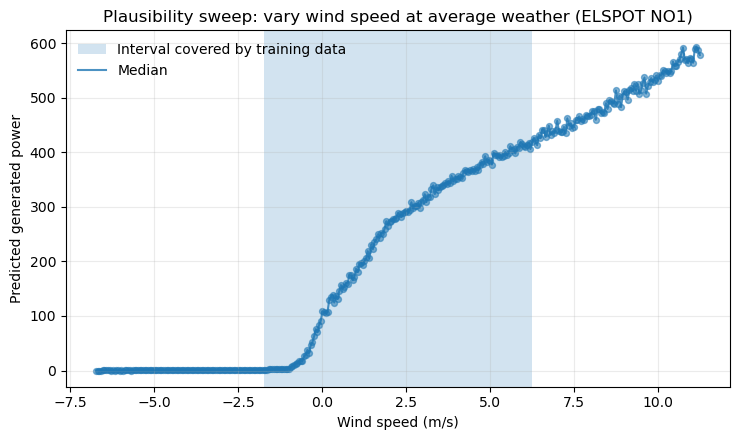

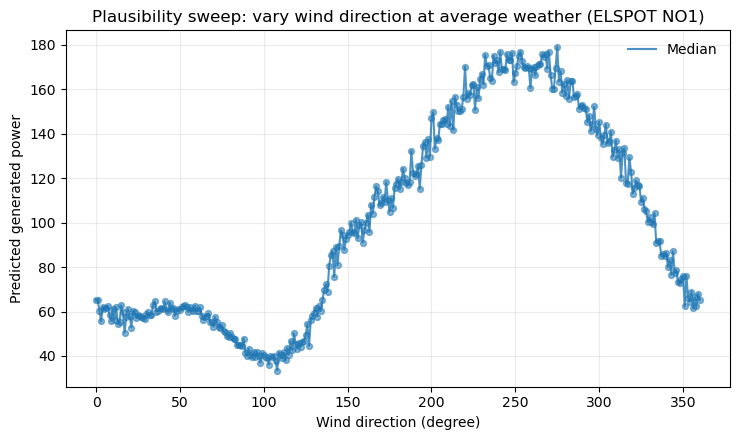

(array([  0.,   1.,   2.,   3.,   4.,   5.,   6.,   7.,   8.,   9.,  10.,
         11.,  12.,  13.,  14.,  15.,  16.,  17.,  18.,  19.,  20.,  21.,
         22.,  23.,  24.,  25.,  26.,  27.,  28.,  29.,  30.,  31.,  32.,
         33.,  34.,  35.,  36.,  37.,  38.,  39.,  40.,  41.,  42.,  43.,
         44.,  45.,  46.,  47.,  48.,  49.,  50.,  51.,  52.,  53.,  54.,
         55.,  56.,  57.,  58.,  59.,  60.,  61.,  62.,  63.,  64.,  65.,
         66.,  67.,  68.,  69.,  70.,  71.,  72.,  73.,  74.,  75.,  76.,
         77.,  78.,  79.,  80.,  81.,  82.,  83.,  84.,  85.,  86.,  87.,
         88.,  89.,  90.,  91.,  92.,  93.,  94.,  95.,  96.,  97.,  98.,
         99., 100., 101., 102., 103., 104., 105., 106., 107., 108., 109.,
        110., 111., 112., 113., 114., 115., 116., 117., 118., 119., 120.,
        121., 122., 123., 124., 125., 126., 127., 128., 129., 130., 131.,
        132., 133., 134., 135., 136., 137., 138., 139., 140., 141., 142.,
        143., 144., 145., 146., 147., 

In [13]:
out_dir = run_plausibility_sweep(
    construct_N=361,
    select_col="wind_direction_10m_x",
    weather_mean=weather_mean,
    weather_stats=weather_stats,
    data=data,
    data_cfg=data_cfg,
    model_cfg=model_cfg,
    file_name=file_name,
)
out_speed = run_plausibility_sweep(
    construct_N=361,
    select_col="wind_speed_10m",
    weather_mean=weather_mean,
    weather_stats=weather_stats,
    data=data,
    data_cfg=data_cfg,
    model_cfg=model_cfg,
    file_name=file_name,
    offset=5,
)

plot_plausibility_sweep(
    out_speed["vals"],
    out_speed["median_mean"],
    offset=5,
    xlabel="Wind speed (m/s)",
    ylabel="Predicted generated power",
    title=f"Plausibility sweep: vary wind speed at average weather ({model_cfg.data.bid_zone})",
)
plot_plausibility_sweep(
    out_dir["vals"],
    out_dir["median_mean"],
    xlabel="Wind direction (degree)",
    ylabel="Predicted generated power",
    title=f"Plausibility sweep: vary wind direction at average weather ({model_cfg.data.bid_zone})",
)

Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-02-16_11-27-43_nowcast_ELSPOT_NO1.pkl
RMSE train: 45.064976
CRPS train:  22.35247510035614
RMSE val: 295.4696841112434
CRPS val:  226.11638878288804 

550


(<Figure size 850x600 with 2 Axes>,
 <PolarAxes: title={'center': 'Plausibility check: speed x direction (ELSPOT NO1)'}>)

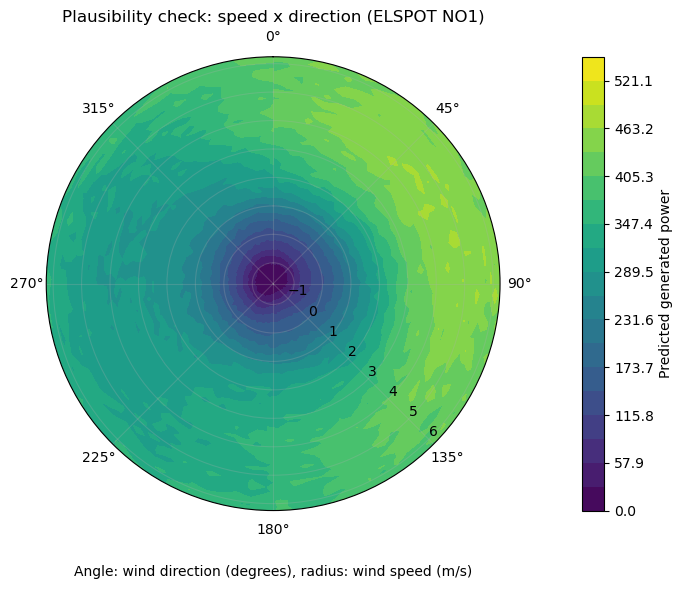

In [14]:
out_2d = run_plausibility_sweep_speed_dir_2d(
    Ns=50,
    Nd=90,
    data=data,
    data_cfg=data_cfg,
    model_cfg=model_cfg,
    file_name=file_name,
    speed_offset=0,
    change_fix_point={"relative_humidity_2m": 2},
)

Z = out_2d["median_mean_grid"]  # (Nd, Ns)
speeds = out_2d["speeds"]  # (Ns,)
dirs = out_2d["directions_deg"]  # (Nd,)
plot_plausibility_polar(
    out_2d["speeds"],
    out_2d["directions_deg"],
    out_2d["median_mean_grid"],
    title=f"Plausibility check: speed x direction ({model_cfg.data.bid_zone})",
    vmax=550,
)

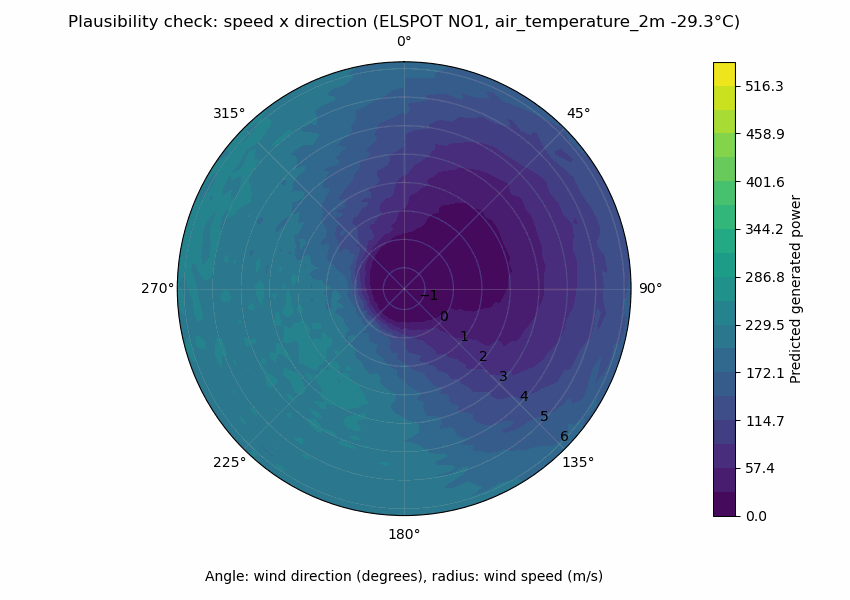

In [15]:
display(Image(f"animation_{model_cfg.data.bid_zone}_air_temperature_2m.gif"))

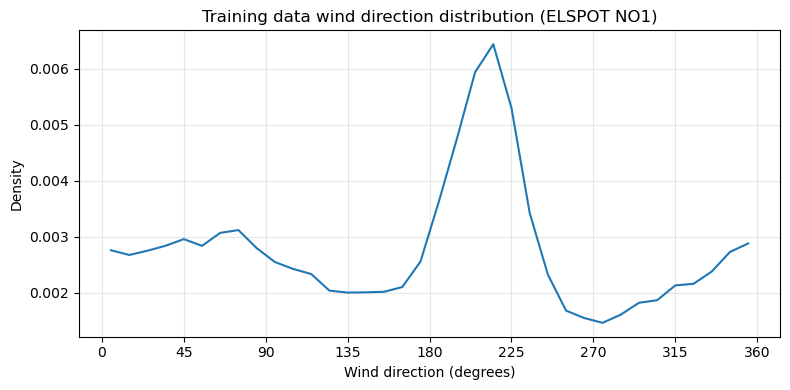

In [16]:
# Plot distribution of wind direction in training data
xdir = data["X_train"][:, :, data["feature_cols"].index("wind_direction_10m_x")]
ydir = data["X_train"][:, :, data["feature_cols"].index("wind_direction_10m_y")]

# radians in [-pi, pi]
angles_rad = np.arctan2(ydir, xdir)

# convert to degrees in [0, 360)
angles_deg_1d = ((np.degrees(angles_rad) + 360) % 360).ravel()

# Histogram values (no plotting yet)
hist, bin_edges = np.histogram(angles_deg_1d, bins=36, range=(0, 360), density=True)

# Bin centers
centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

plt.figure(figsize=(8, 4))
plt.plot(centers, hist)
plt.xlabel("Wind direction (degrees)")
plt.ylabel("Density")
plt.title(f"Training data wind direction distribution ({model_cfg.data.bid_zone})")
plt.xticks(np.arange(0, 361, 45))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

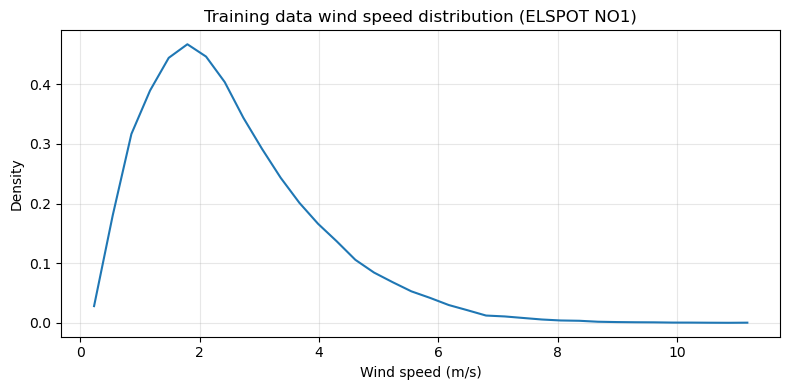

In [17]:
# Plot distribution of wind speed in training data
speed = data["X_train"][:, :, data["feature_cols"].index("wind_speed_10m")]

speed_1d = (speed).ravel()

# Histogram values (no plotting yet)
hist, bin_edges = np.histogram(
    speed_1d, bins=36, range=(speed.min(), speed.max()), density=True
)

# Bin centers
centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
mu = scalar_params["scaler_params"]["mean"]["wind_speed_10m"]
sigma = scalar_params["scaler_params"]["std"]["wind_speed_10m"]

unnormalized_center = centers * sigma + mu

plt.figure(figsize=(8, 4))
plt.plot(unnormalized_center, hist)
plt.xlabel("Wind speed (m/s)")
plt.ylabel("Density")
plt.title(f"Training data wind speed distribution ({model_cfg.data.bid_zone})")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()